# From Statistical Targets to Financial Decisions

The equation separates a population target, its sample estimate, and the expected loss of an action:

$$
\theta=\theta(P),\qquad \widehat\theta=T(X_1,\ldots,X_n),\qquad
R_P(a)=\mathbb E_P[L(Y,a)].
$$

Here, $P$ is the population distribution; $\theta(P)$ is the target quantity; $\widehat\theta$ is its estimate. $T$ is the rule that turns observations $X_1,\ldots,X_n$ into an estimate; $n$ is the sample size. $a$ is an action; $Y$ is the outcome; $L(Y,a)$ is its loss; $R_P(a)$ is expected loss under $P.$

In [1]:
using RiskLabAI, Random, Statistics, LinearAlgebra, DataFrames, Dates, Plots
include(joinpath("..", "support", "BookSupport.jl"))
using .BookSupport
import .BookSupport: palette
@assert pkgversion(RiskLabAI) == v"1.1.0"
configure_plots!()
paths = output_paths("01_mathematical_language");
raw = load_binance()


Row,Open time,Open,High,Low,close,volume,Close time,quote_volume,trades,Buyer base volume,Buyer quote volume,Unused,time
,Int64,Float64,Float64,Float64,Float64,Float64,Int64,Float64,Int64,Float64,Float64,Int64,DateTime
1,1609459200000,28923.6,28961.7,28913.1,28961.7,27.457,1609459259999,794382.0,1292,16.7772,4.85391e5,0,2021-01-01T00:00:00
2,1609459260000,28961.7,29017.5,28961.0,29009.9,58.4775,1609459319999,1.6958e6,1651,33.7338,9.78176e5,0,2021-01-01T00:01:00
3,1609459320000,29009.5,29016.7,28973.6,28989.3,42.4703,1609459379999,1.23136e6,986,13.2474,3.84077e5,0,2021-01-01T00:02:00
4,1609459380000,28989.7,28999.8,28972.3,28982.7,30.3607,1609459439999,8.80017e5,959,9.45603,2.74083e5,0,2021-01-01T00:03:00
5,1609459440000,28982.7,28995.9,28971.8,28975.7,24.1243,1609459499999,6.99226e5,726,6.81464,1.97519e5,0,2021-01-01T00:04:00
6,1609459500000,28975.7,28979.5,28933.2,28937.1,22.396,1609459559999,6.48323e5,952,9.12755,2.64218e5,0,2021-01-01T00:05:00
7,1609459560000,28937.1,28963.2,28937.1,28943.9,20.4803,1609459619999,5.92926e5,750,5.44417,1.57609e5,0,2021-01-01T00:06:00
8,1609459620000,28943.9,28954.5,28930.0,28934.8,20.9623,1609459679999,6.06581e5,782,13.1547,3.80651e5,0,2021-01-01T00:07:00
9,1609459680000,28934.8,28936.2,28889.2,28900.0,52.6455,1609459739999,1.52174e6,886,28.44,8.21806e5,0,2021-01-01T00:08:00


## From population targets to sample estimates

The first two expressions define the population mean and covariance, while the third estimates the mean from a sample:

$$
\mu=\mathbb E[X],\qquad
\Sigma=\mathbb E[(X-\mu)(X-\mu)^{\mathsf T}],\qquad
\widehat\mu=\frac{1}{n}\sum_{i=1}^{n}X_i.
$$

Here, $X$ is a random vector; $\mu$ is its population mean; $\Sigma$ is its population covariance matrix. $X_i$ is observation $i$; $n$ is the number of observations; $\widehat\mu$ is the sample mean; $\mathsf T$ denotes transpose.

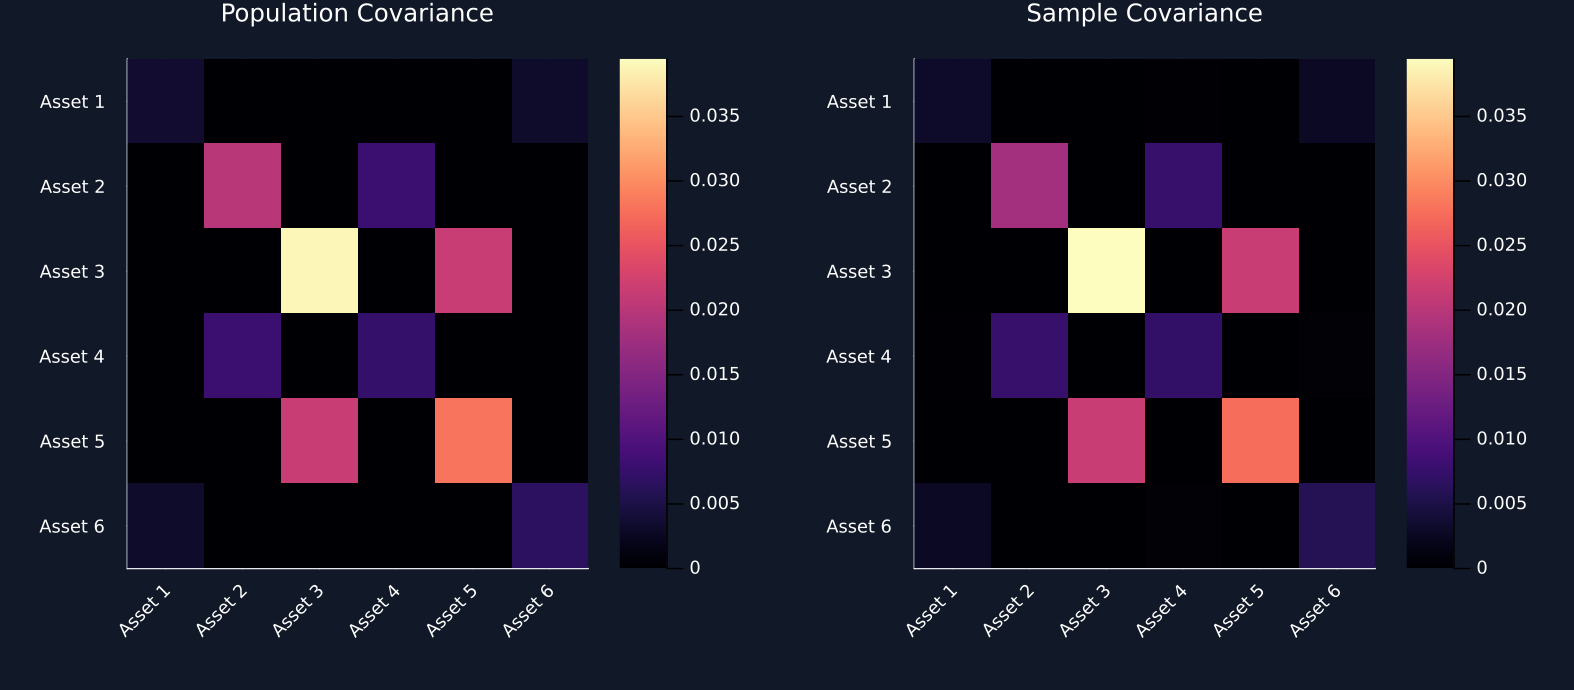

In [2]:
population_mean_vector, population_covariance = RiskLabAI.Data.form_true_matrix(3, 2, .65; rng=Xoshiro(20260925))
population_mean = reshape(population_mean_vector, :, 1)
sample_mean_vector, sample_covariance = RiskLabAI.Data.simulates_cov_mu(population_mean, population_covariance, 240; shrink=false, rng=Xoshiro(20260926))
sample_mean = reshape(sample_mean_vector, :, 1)
asset_labels = ["Asset $index" for index in 1:6]
population_covariance_frame = hcat(DataFrame("Asset"=>asset_labels), DataFrame(population_covariance, asset_labels))
sample_covariance_frame = hcat(DataFrame("Asset"=>asset_labels), DataFrame(sample_covariance, asset_labels))
save_data(population_covariance_frame, paths, "population_covariance")
save_data(sample_covariance_frame, paths, "sample_covariance")
common_limit = max(maximum(population_covariance), maximum(sample_covariance))
population_panel = heatmap(population_covariance; clims=(0, common_limit), color=:magma, xticks=(1:6, asset_labels), yticks=(1:6, asset_labels), xrotation=45, yflip=true, title="Population Covariance")
sample_panel = heatmap(sample_covariance; clims=(0, common_limit), color=:magma, xticks=(1:6, asset_labels), yticks=(1:6, asset_labels), xrotation=45, yflip=true, title="Sample Covariance")
figure = plot(population_panel, sample_panel; layout=(1, 2), size=(1050, 460), bottom_margin=12Plots.mm)
save_figure(figure, paths, "covariance_estimand_estimator")


## Choosing optimal actions from a loss function

Squared loss is minimized by the mean, while absolute loss is minimized by a median:

$$
a_2^*=\arg\min_a\mathbb E[(Y-a)^2]=\mathbb E[Y],
\qquad
a_1^*\in\arg\min_a\mathbb E[|Y-a|]=\operatorname{Median}(Y).
$$

Here, $Y$ is the uncertain outcome; $a$ is a candidate action; $a_2^*$ and $a_1^*$ are optimal actions. $\mathbb E$ denotes expectation; $\arg\min$ selects an action with the smallest expected loss; $\operatorname{Median}(Y)$ is any median of $Y.$

Row,Field,Value
,String,String
1,Provider,Binance Data Vision
2,Archive,BTCUSDT-1m-2021-01.zip
3,Public access,Direct public download
4,Sample,January 2021
5,Daily observations,30


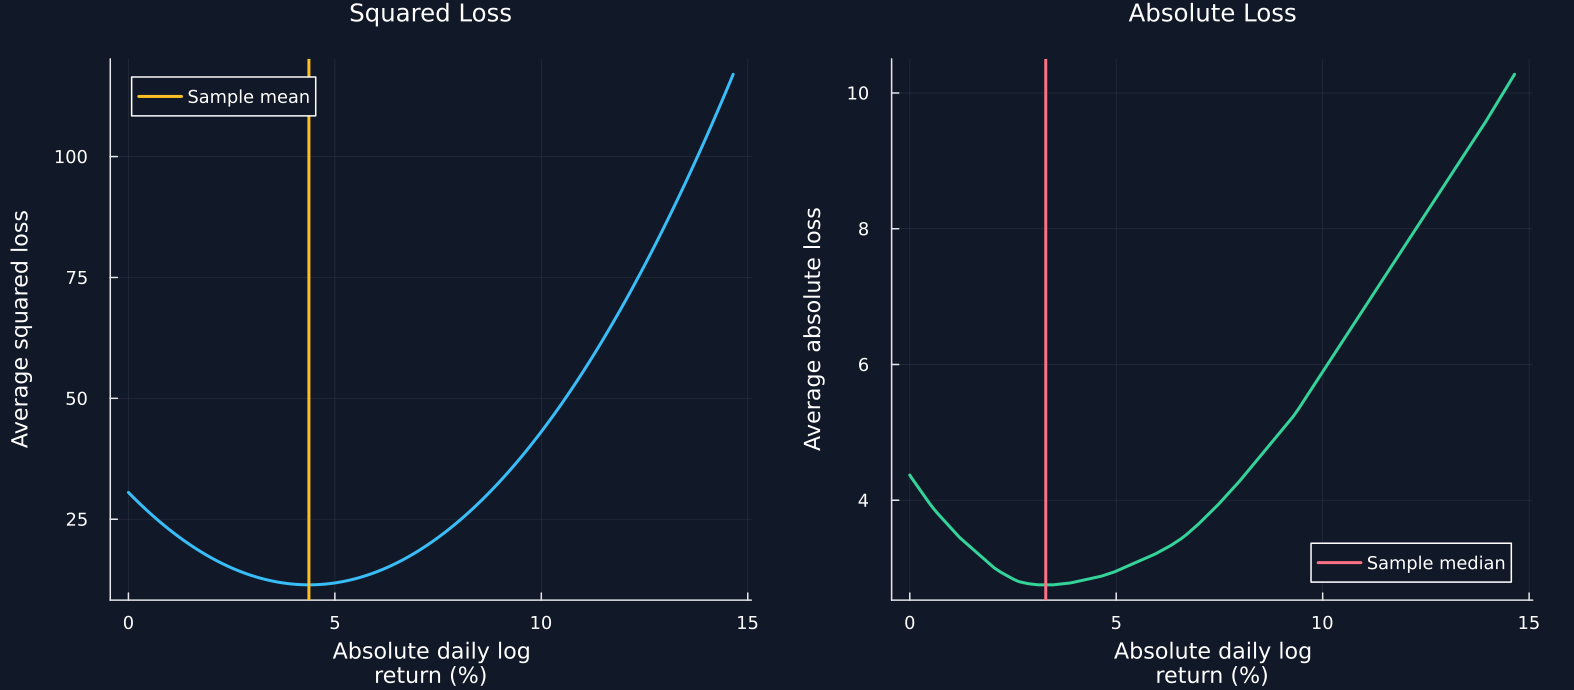

In [3]:
raw.date = Date.(raw.time)
daily_close = combine(groupby(raw, :date; sort=true), :close=>last=>:close)
outcomes = abs.(100 .* diff(log.(daily_close.close)))
candidate_actions = collect(range(0., 1.05*maximum(outcomes); length=20001))
squared_loss = [mean((outcomes.-action).^2) for action in candidate_actions]
absolute_loss = [mean(abs.(outcomes.-action)) for action in candidate_actions]
mean_action, median_action = mean(outcomes), median(outcomes)
loss_curve = DataFrame("Absolute daily log return (%)"=>candidate_actions, "Average squared loss"=>squared_loss, "Average absolute loss"=>absolute_loss, "Sample mean"=>fill(mean_action, length(candidate_actions)), "Sample median"=>fill(median_action, length(candidate_actions)))
save_data(loss_curve, paths, "loss_decisions")
loss_data_summary = DataFrame("Field"=>["Provider", "Archive", "Public access", "Sample", "Daily observations"], "Value"=>["Binance Data Vision", "BTCUSDT-1m-2021-01.zip", "Direct public download", "January 2021", string(length(outcomes))])
display(loss_data_summary)
squared_panel = plot(candidate_actions, squared_loss; color=palette.cyan, xlabel="Absolute daily log\nreturn (%)", ylabel="Average squared loss", title="Squared Loss", label="")
vline!(squared_panel, [mean_action]; color=palette.amber, label="Sample mean")
absolute_panel = plot(candidate_actions, absolute_loss; color=palette.green, xlabel="Absolute daily log\nreturn (%)", ylabel="Average absolute loss", title="Absolute Loss", label="")
vline!(absolute_panel, [median_action]; color=palette.rose, label="Sample median")
figure = plot(squared_panel, absolute_panel; layout=(1, 2), size=(1050, 460))
save_figure(figure, paths, "loss_decisions")


## Portfolio Decision

The first expression gives fully invested minimum-variance weights, and the second measures the variance of estimated weights:

$$
w^*(\Sigma)=\frac{\Sigma^{-1}\mathbf 1}{\mathbf 1^{\mathsf T}\Sigma^{-1}\mathbf 1},
\qquad
\mathcal R(\widehat w;\Sigma)=\widehat w^{\mathsf T}\Sigma\widehat w.
$$

Here, $\Sigma$ is the asset-return covariance matrix; $\Sigma^{-1}$ is its inverse; $\mathbf 1$ is a vector of ones. $w^*(\Sigma)$ is the population choice; $\widehat w$ is an estimated weight vector; $\mathcal R(\widehat w;\Sigma)$ is its population variance.

In [4]:
population_weights = minimum_variance_weights(population_covariance)
plug_in_weights = minimum_variance_weights(sample_covariance)
population_risk = dot(population_weights, population_covariance*population_weights)
plug_in_population_risk = dot(plug_in_weights, population_covariance*plug_in_weights)
estimation_summary = DataFrame("Object"=>["Expected return vector", "Covariance matrix", "Minimum-variance decision"], "Population magnitude"=>[norm(population_mean), norm(population_covariance), population_risk], "Sample magnitude"=>[norm(sample_mean), norm(sample_covariance), plug_in_population_risk], "Estimation or decision error"=>[norm(sample_mean-population_mean), norm(sample_covariance-population_covariance), plug_in_population_risk-population_risk])
save_table(estimation_summary, paths, "estimation_decision_summary"; caption="Population targets, sample estimates, and the induced portfolio decision error.", label="tab:estimation-decision-summary")


Row,Object,Population magnitude,Sample magnitude,Estimation or decision error
,String,Float64,Float64,Float64
1,Expected return vector,0.628045,0.637027,0.0176533
2,Covariance matrix,0.0621599,0.0614207,0.003013
3,Minimum-variance decision,0.00215009,0.00217725,2.71656e-5


## Tests

In [5]:
@assert size(population_mean) == size(sample_mean) == (6, 1)
@assert size(population_covariance) == size(sample_covariance) == (6, 6)
@assert population_covariance ≈ population_covariance'
@assert sample_covariance ≈ sample_covariance'
@assert minimum(eigvals(Symmetric(population_covariance))) > 0
@assert minimum(eigvals(Symmetric(sample_covariance))) > 0
@assert sum(population_weights) ≈ 1
@assert sum(plug_in_weights) ≈ 1
@assert plug_in_population_risk >= population_risk-1e-12
@assert length(outcomes) == 30
@assert abs(candidate_actions[argmin(squared_loss)]-mean_action) <= maximum(diff(candidate_actions))
@assert isapprox(minimum(absolute_loss), mean(abs.(outcomes.-median_action)); rtol=1e-8, atol=1e-10)
@assert nrow(estimation_summary) == 3
@assert maximum(abs.(squared_loss.-(var(outcomes; corrected=false).+(candidate_actions.-mean_action).^2))) < 1e-10
